# Курсова робота: дослідження та підготовка даних для розв'язання задачі машинного навчання**Предметна область:** криптовалютний ринок.**Задача:** бінарна класифікація - чи буде дохідність монети за наступні сім дніввищою за дохідність медіанної монети того самого тижня.Пашко Назарій, СА-32, Львів-2026.

## 1. Імпорти, налаштування та SEED

In [1]:
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import (chi2_contingency, kruskal, mannwhitneyu, pointbiserialr,
                         shapiro, skew)
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report,
                             confusion_matrix, f1_score, precision_score, recall_score,
                             roc_auc_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

SEED = 42
np.random.seed(SEED)
warnings.filterwarnings("ignore")
pd.set_option("display.width", 120)
sns.set_theme(style="whitegrid", font_scale=0.9)
plt.rcParams["figure.dpi"] = 110
KEY = {}  # ключові результати для таблиць у тексті роботи
print("SEED =", SEED)

SEED = 42


## 2. Завантаження сирих данихСирий датасет зібрано скриптом `data/raw/build_weekly_panel.py` з денної історіїBinance і довідників CoinGecko. Одиниця спостереження - монета в конкретний тиждень,момент прогнозу - закриття торгів у неділю, горизонт - сім днів.

In [2]:
RAW_PATH = "data/raw/raw_crypto_weekly_panel.csv.gz"
df_raw = pd.read_csv(RAW_PATH, parse_dates=["checkpoint"])

print("Розмір сирого датасету:", df_raw.shape)
print("Період:", df_raw["checkpoint"].min().date(), "-", df_raw["checkpoint"].max().date())
print("Унікальних монет:", df_raw["symbol"].nunique())
print("Унікальних тижнів:", df_raw["checkpoint"].nunique())
per_week = df_raw.groupby("checkpoint").size()
print("Монет на тиждень: від", per_week.min(), "до", per_week.max())

Розмір сирого датасету: (65820, 32)
Період: 2021-01-03 - 2026-09-13
Унікальних монет: 384
Унікальних тижнів: 298
Монет на тиждень: від 85 до 384


## 3. Початкове технічне профілювання

In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 65820 entries, 0 to 65819
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   symbol                   65820 non-null  str           
 1   coingecko_id             65820 non-null  str           
 2   checkpoint               65820 non-null  datetime64[us]
 3   sector                   55312 non-null  str           
 4   market_regime            65820 non-null  str           
 5   close_t0                 65820 non-null  float64       
 6   trailing_return_7d       65820 non-null  float64       
 7   trailing_return_30d      65820 non-null  float64       
 8   trailing_return_90d      65820 non-null  float64       
 9   trailing_volatility_7d   65820 non-null  float64       
 10  trailing_volatility_30d  65820 non-null  float64       
 11  avg_quote_volume_30d     65794 non-null  float64       
 12  trailing_volume_trend    65786 non-null  fl

In [4]:
profile = pd.DataFrame({
    "тип": df_raw.dtypes.astype(str),
    "пропусків": df_raw.isna().sum(),
    "пропусків, %": (df_raw.isna().mean() * 100).round(2),
    "унікальних": df_raw.nunique(),
})
profile

,тип,пропусків,"пропусків, %",унікальних
symbol,str,0,0.00,384
coingecko_id,str,0,0.00,384
checkpoint,datetime64[us],0,0.00,298
sector,str,10508,15.96,15
market_regime,str,0,0.00,3
close_t0,float64,0,0.00,30817
trailing_return_7d,float64,0,0.00,62055
trailing_return_30d,float64,0,0.00,63730
trailing_return_90d,float64,0,0.00,64531
trailing_volatility_7d,float64,0,0.00,65798


In [5]:
print("Точних дублікатів рядків:", int(df_raw.duplicated().sum()))
print("Дублікатів пари (symbol, checkpoint):",
      int(df_raw.duplicated(subset=["symbol", "checkpoint"]).sum()))
const_cols = [c for c in df_raw.columns if df_raw[c].nunique(dropna=False) <= 1]
print("Константних стовпців:", const_cols if const_cols else "немає")
print()
print("Розподіл цільової змінної beat_market (лише для вибору способу поділу):")
print(df_raw["beat_market"].value_counts(normalize=True).round(4).to_string())
print("Пропусків у цілі:", int(df_raw["beat_market"].isna().sum()))

Точних дублікатів рядків: 0
Дублікатів пари (symbol, checkpoint): 0
Константних стовпців: немає

Розподіл цільової змінної beat_market (лише для вибору способу поділу):
beat_market
0    0.5011
1    0.4989
Пропусків у цілі: 0


In [6]:
def domain_checks(df):
    num = df.select_dtypes("number")
    return pd.DataFrame([
        {"правило": "rsi_14 в межах 0-100",
         "порушень": int(((df["rsi_14"] < 0) | (df["rsi_14"] > 100)).sum())},
        {"правило": "волатильність невід'ємна",
         "порушень": int((df["trailing_volatility_30d"] < 0).sum())},
        {"правило": "обсяг торгів невід'ємний",
         "порушень": int((df["avg_quote_volume_30d"] < 0).sum())},
        {"правило": "вік монети не менший за 98 днів",
         "порушень": int((df["coin_age_days"] < 98).sum())},
        {"правило": "дохідність не менша за -100 %",
         "порушень": int((df["forward_return"] < -1).sum())},
        {"правило": "просадка в межах від -100 % до 0",
         "порушень": int(((df["drawdown_from_high_180d"] < -1)
                          | (df["drawdown_from_high_180d"] > 0)).sum())},
        {"правило": "числові значення скінченні",
         "порушень": int(np.isinf(num).sum().sum())},
    ])


domain_checks(df_raw)

,правило,порушень
0,rsi_14 в межах 0-100,0
1,волатильність невід'ємна,0
2,обсяг торгів невід'ємний,0
3,вік монети не менший за 98 днів,0
4,дохідність не менша за -100 %,0
5,просадка в межах від -100 % до 0,0
6,числові значення скінченні,0


In [7]:
breaks = pd.read_csv("data/price_breaks_weekly.csv")
print("Паузи в торгах на Binance тривалістю 3 і більше днів:")
print(breaks.rename(columns={"останній день до паузи": "до паузи", "відновлення торгів": "відновлення",
                             "днів без торгів": "днів"}).to_string(index=False))
in_window = df_raw["missing_days_in_window"] >= 3
print()
print("Записів, у вікні ознак або цілі яких була пауза:", int(in_window.sum()))
print(df_raw.loc[in_window, "symbol"].value_counts().to_string())
volume_na = df_raw[["avg_quote_volume_30d", "trailing_volume_trend", "volume_7d_vs_30d"]].isna().any(axis=1)
print()
print("Записів з пропусками в ознаках обсягу:", int(volume_na.sum()),
      "| з них у вікні з паузою в торгах:", int((volume_na & in_window).sum()))

Паузи в торгах на Binance тривалістю 3 і більше днів:
   symbol   до паузи відновлення  днів  ціна до  ціна після  зміна, разів
  CVCUSDT 2022-12-09  2023-05-12   153  0.09780     0.08910        0.9110
 LUNAUSDT 2022-05-13  2022-05-31    17  0.00005     8.87000   177400.0000
QUICKUSDT 2023-07-17  2023-07-21     3 74.20000     0.05967        0.0008
STRAXUSDT 2024-03-20  2024-03-28     7  1.42300     0.14600        0.1026
  SUNUSDT 2021-06-14  2021-06-18     3 27.57200     0.03305        0.0012

Записів, у вікні ознак або цілі яких була пауза: 157
symbol
CVCUSDT      48
LUNAUSDT     28
SUNUSDT      27
QUICKUSDT    27
STRAXUSDT    27

Записів з пропусками в ознаках обсягу: 40 | з них у вікні з паузою в торгах: 40


## 4. Структурне очищення

In [8]:
build_audit = pd.read_csv("data/build_audit_weekly.csv")
print("Записи, вилучені під час побудови панелі з первинних даних:")
for _, r in build_audit.iterrows():
    print(f"{r['кількість']:>6} {r['одиниця']:<8} {r['етап']}")
print()
join_audit = pd.read_csv("data/join_audit_weekly.csv")
unresolved = join_audit[join_audit["status"] == "unresolved_no_cgid"]
print("Зіставлення символів Binance з CoinGecko:")
print(join_audit["status"].value_counts().to_string())
print("Приклади незіставлених символів:", ", ".join(unresolved["symbol"].head(5)))

Записи, вилучені під час побудови панелі з первинних даних:
    40 монет    монети з історією коротшою за 105 днів (виключено повністю)
 69982 записів  пари монета-тиждень, коли монета вже торгувалась
  4162 записів  вилучено: монета молодша за 98 днів (немає 90-денної історії для ознак)
     0 записів  вилучено: невідома ціль (немає ціни через 7 днів, розрив у даних біржі)
     0 записів  вилучено: немає ціни 90 днів тому (розрив у даних біржі)
     0 записів  вилучено: невідома дохідність BTC за тиждень
 65820 записів  залишилось у сирій панелі

Зіставлення символів Binance з CoinGecko:
status
resolved              353
resolved_no_sector     77
unresolved_no_cgid     55
Приклади незіставлених символів: 1000CATUSDT, 1000CHEEMSUSDT, 1000SATSUSDT, 1MBABYDOGEUSDT, ACHUSDT


In [9]:
df_clean = df_raw.copy()
sector_missing_before = int(df_clean["sector"].isna().sum())
df_clean["sector"] = df_clean["sector"].fillna("Other")
rows_before = len(df_clean)
df_clean = df_clean[df_clean["beat_market"].notna()]
gap_rows = df_clean["missing_days_in_window"] >= 3
df_clean = df_clean[~gap_rows]
luna_rows = df_clean["symbol"] == "LUNAUSDT"
df_clean = df_clean[~luna_rows].copy()
df_clean["symbol"] = df_clean["symbol"].str.upper().str.strip()

cleaning_log = pd.DataFrame([
    {"проблема": "сектор не визначений", "виявлення": "sector.isna()",
     "дія": "явна категорія Other", "записів": sector_missing_before},
    {"проблема": "невідома ціль", "виявлення": "beat_market.isna()",
     "дія": "вилучення до поділу", "записів": rows_before - len(df_raw.dropna(subset=["beat_market"]))},
    {"проблема": "пауза в торгах у вікні ознак або цілі", "виявлення": "missing_days_in_window >= 3",
     "дія": "вилучення до поділу", "записів": int(gap_rows.sum())},
    {"проблема": "тикер двох різних активів", "виявлення": "symbol = LUNAUSDT",
     "дія": "вилучення символу", "записів": int(luna_rows.sum())},
    {"проблема": "монета молодша за 98 днів", "виявлення": "coin_age_days < 98",
     "дія": "вилучено під час побудови", "записів": int(build_audit["кількість"].iloc[2])},
    {"проблема": "символ без монети CoinGecko", "виявлення": "status = unresolved_no_cgid",
     "дія": "вилучено під час побудови", "записів": len(unresolved)},
    {"проблема": "формат тікера", "виявлення": "регістр і пробіли",
     "дія": "верхній регістр, без пробілів", "записів": 0},
])
cleaning_log

,проблема,виявлення,дія,записів
0,сектор не визначений,sector.isna(),явна категорія Other,10508
1,невідома ціль,beat_market.isna(),вилучення до поділу,0
2,пауза в торгах у вікні ознак або цілі,missing_days_in_window >= 3,вилучення до поділу,157
3,тикер двох різних активів,symbol = LUNAUSDT,вилучення символу,270
4,монета молодша за 98 днів,coin_age_days < 98,вилучено під час побудови,4162
5,символ без монети CoinGecko,status = unresolved_no_cgid,вилучено під час побудови,55
6,формат тікера,регістр і пробіли,"верхній регістр, без пробілів",0


## 5. Контроль після структурного очищення

In [10]:
print("Схема збережена:", list(df_clean.columns) == list(df_raw.columns))
print("Типи збережені:", (df_clean.dtypes == df_raw.dtypes).all())
print("Точних дублікатів:", int(df_clean.duplicated().sum()))
print("Рядків до / після:", len(df_raw), "/", len(df_clean))
print("Пропусків sector до / після:", int(df_raw["sector"].isna().sum()), "/",
      int(df_clean["sector"].isna().sum()))
print("Пропусків у цілі:", int(df_clean["beat_market"].isna().sum()),
      "| значення цілі:", sorted(df_clean["beat_market"].unique()))
print("Порушень доменних правил:", int(domain_checks(df_clean)["порушень"].sum()))
print("Записів з паузою в торгах у вікні:", int((df_clean["missing_days_in_window"] >= 3).sum()),
      "| записів LUNAUSDT:", int((df_clean["symbol"] == "LUNAUSDT").sum()))
print()
print("Категорії market_regime:", sorted(df_clean["market_regime"].unique()))
print("Кількість секторів:", df_clean["sector"].nunique())
print(df_clean["sector"].value_counts().to_string())

Схема збережена: True
Типи збережені: True
Точних дублікатів: 0
Рядків до / після: 65820 / 65393
Пропусків sector до / після: 10508 / 0
Пропусків у цілі: 0 | значення цілі: [np.int64(0), np.int64(1)]
Порушень доменних правил: 0
Записів з паузою в торгах у вікні: 0 | записів LUNAUSDT: 0

Категорії market_regime: ['bear', 'bull', 'sideways']
Кількість секторів: 16
sector
Layer-1             12881
Other               10162
DeFi                 7244
AI                   6237
DEX                  5495
Gaming               5431
Layer-2              3850
Meme                 3055
RWA                  2994
Oracle/Infra         2257
NFT                  1853
Infrastructure       1839
Privacy               858
Exchange Token        513
Stablecoin            444
Metaverse/Gaming      280


In [11]:
df_clean.to_csv("data/structurally_cleaned/structurally_cleaned_weekly_panel.csv.gz",
                index=False, compression="gzip", encoding="utf-8")
na_left = df_clean.isna().sum()
print("Збережено структурно очищений датасет:", df_clean.shape)
print("Пропуски, залишені для оброблення всередині конвеєра:")
print(na_left[na_left > 0].to_string())

Збережено структурно очищений датасет: (65393, 32)
Пропуски, залишені для оброблення всередині конвеєра:
Series([], )


## 6. Формування train/testДані часові й групові. Часовий поділ має пріоритет: усі тижні train передують усімтижням test, межу обрано так, щоб у train потрапило 80 % записів.

In [12]:
rows_per_week = df_clean.groupby("checkpoint").size().sort_index()
share_cum = rows_per_week.cumsum() / len(df_clean)
n_train_weeks = int((share_cum < 0.80).sum())
split_week = rows_per_week.index[n_train_weeks - 1]

train_df = df_clean[df_clean["checkpoint"] <= split_week].reset_index(drop=True)
test_df = df_clean[df_clean["checkpoint"] > split_week].reset_index(drop=True)

for name, part in [("train", train_df), ("test", test_df)]:
    print(f"{name}: {len(part)} рядків ({len(part) / len(df_clean) * 100:.1f} %), "
          f"{part['checkpoint'].nunique()} тижнів, "
          f"{part['checkpoint'].min().date()} - {part['checkpoint'].max().date()}")

train: 52133 рядків (79.7 %), 262 тижнів, 2021-01-03 - 2026-01-04
test: 13260 рядків (20.3 %), 36 тижнів, 2026-01-11 - 2026-09-13


In [13]:
print("Перетин тижнів:", len(set(train_df["checkpoint"]) & set(test_df["checkpoint"])))
pairs_train = set(zip(train_df["symbol"], train_df["checkpoint"]))
pairs_test = set(zip(test_df["symbol"], test_df["checkpoint"]))
print("Перетин пар (монета, тиждень):", len(pairs_train & pairs_test))
print("Останнє цільове вікно train закінчується:",
      (split_week + pd.Timedelta(days=7)).date(),
      "| перший прогноз test:", test_df["checkpoint"].min().date())
print()
print("Частка класу 1: train", round(train_df["beat_market"].mean(), 4),
      "| test", round(test_df["beat_market"].mean(), 4))
print()
print("Ринкові режими (кількість тижнів):")
print(pd.DataFrame({
    "train": train_df.groupby("checkpoint")["market_regime"].first().value_counts(),
    "test": test_df.groupby("checkpoint")["market_regime"].first().value_counts(),
}).fillna(0).astype(int).to_string())

Перетин тижнів: 0


Перетин пар (монета, тиждень): 0
Останнє цільове вікно train закінчується: 2026-01-11 | перший прогноз test: 2026-01-11

Частка класу 1: train 0.4989 | test 0.4995

Ринкові режими (кількість тижнів):
               train  test
market_regime             
bear              75    25
bull             118     5
sideways          69     6


## 7. Статистичне дослідження trainТут і до кроку 18 використовується **тільки train**.

In [14]:
COIN_FEATURES = [
    "trailing_return_7d", "trailing_return_30d", "trailing_return_90d",
    "trailing_volatility_7d", "trailing_volatility_30d", "avg_quote_volume_30d",
    "trailing_volume_trend", "volume_7d_vs_30d", "drawdown_from_high_180d",
    "max_daily_return_30d", "rsi_14", "macd_hist_norm", "bollinger_pctb_20",
    "btc_corr_90d", "btc_beta_90d", "coin_age_days",
]
MARKET_FEATURES = ["btc_trailing_return_30d", "btc_trailing_return_90d", "btc_rsi_14"]
CAT_FEATURES = ["sector", "market_regime"]

print("Записів у train:", len(train_df), "| обсяг торгів подано в мільйонах доларів")
desc = train_df[COIN_FEATURES].describe().T.drop(columns="count")
desc.loc["avg_quote_volume_30d"] /= 1e6
desc.style.format("{:.3f}")

Записів у train: 52133 | обсяг торгів подано в мільйонах доларів


,mean,std,min,25%,50%,75%,max
trailing_return_7d,0.004,0.177,-0.782,-0.084,-0.009,0.068,5.173
trailing_return_30d,0.024,0.455,-0.817,-0.197,-0.058,0.121,17.236
trailing_return_90d,0.127,1.287,-0.912,-0.367,-0.116,0.219,43.380
trailing_volatility_7d,0.051,0.038,0.000,0.029,0.042,0.061,1.499
trailing_volatility_30d,0.055,0.031,0.000,0.037,0.049,0.064,0.738
avg_quote_volume_30d,33.279,146.339,0.034,1.925,4.854,16.740,4838.468
trailing_volume_trend,0.465,3.103,-0.950,-0.429,-0.141,0.422,246.251
volume_7d_vs_30d,0.005,0.539,-0.945,-0.348,-0.118,0.207,3.211
drawdown_from_high_180d,-0.459,0.225,-0.971,-0.636,-0.482,-0.290,0.000
max_daily_return_30d,0.143,0.143,0.000,0.073,0.108,0.162,3.931


In [15]:
print("Асиметрія числових ознак (train):")
print(train_df[COIN_FEATURES].apply(lambda s: skew(s.dropna())).round(1)
      .sort_values().to_string())
print()
print("Розподіл цілі в train:",
      train_df["beat_market"].value_counts(normalize=True).round(4).to_dict())
print("Частоти ринкових режимів (рядки):",
      train_df["market_regime"].value_counts(normalize=True).round(3).to_dict())

Асиметрія числових ознак (train):
macd_hist_norm             -1.3
btc_corr_90d               -0.9
drawdown_from_high_180d     0.2
bollinger_pctb_20           0.3
rsi_14                      0.5
coin_age_days               0.5
btc_beta_90d                1.4
volume_7d_vs_30d            1.8
trailing_volatility_30d     4.5
trailing_return_7d          4.7
trailing_volatility_7d      6.5
trailing_return_30d         7.4
max_daily_return_30d        7.4
trailing_return_90d        10.3
avg_quote_volume_30d       12.7
trailing_volume_trend      22.1

Розподіл цілі в train: {0: 0.5011, 1: 0.4989}
Частоти ринкових режимів (рядки): {'bull': 0.432, 'sideways': 0.292, 'bear': 0.276}


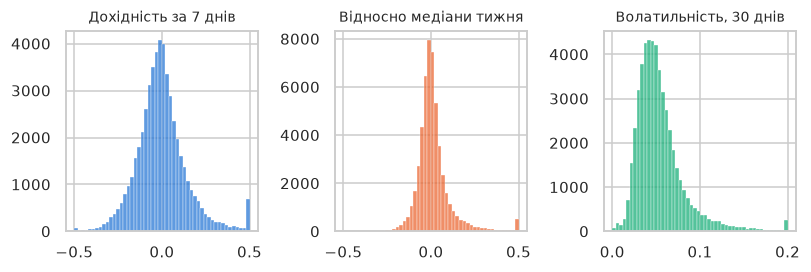

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(7.5, 2.6))
for ax, col, title, lim, color in [
        (axes[0], "forward_return", "Дохідність за 7 днів", (-0.5, 0.5), "#2a78d6"),
        (axes[1], "relative_forward_return", "Відносно медіани тижня", (-0.5, 0.5), "#eb6834"),
        (axes[2], "trailing_volatility_30d", "Волатильність, 30 днів", (0, 0.2), "#1baf7a")]:
    sns.histplot(train_df[col].clip(*lim), bins=50, ax=ax, color=color)
    ax.set_title(title, fontsize=9)
    ax.set_xlabel("")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

In [17]:
ct = pd.crosstab(train_df["sector"], train_df["beat_market"], normalize="index").mul(100).round(1)
ct.columns = ["не випередила, %", "випередила, %"]
ct["записів"] = train_df["sector"].value_counts()
ct.sort_values("випередила, %", ascending=False)

,"не випередила, %","випередила, %",записів
sector,,,
Exchange Token,38.8,61.2,441
Stablecoin,43.8,56.2,226
Layer-1,48.3,51.7,10631
Privacy,48.8,51.2,750
Oracle/Infra,48.9,51.1,1883
RWA,49.1,50.9,2381
DEX,49.1,50.9,4499
Other,49.2,50.8,8191
DeFi,50.4,49.6,5697


## 8. Аналіз пропусків і потенційних викидів на train

In [18]:
model_cols = COIN_FEATURES + MARKET_FEATURES + CAT_FEATURES
na_train = train_df[model_cols].isna().sum()
print("Пропусків у ознаках train після структурного очищення:", int(na_train.sum()))
print("Ознак із пропусками:", list(na_train[na_train > 0].index) or "немає")
print()
print("Пропуски сирих даних (крок 3) містились лише у записах з паузою в торгах")
print("і були вилучені разом із ними на кроці 4. Механізм - MAR: пропуск повністю")
print("пояснюється спостережуваною змінною missing_days_in_window, а не значенням ознаки.")

Пропусків у ознаках train після структурного очищення: 0
Ознак із пропусками: немає

Пропуски сирих даних (крок 3) містились лише у записах з паузою в торгах
і були вилучені разом із ними на кроці 4. Механізм - MAR: пропуск повністю
пояснюється спостережуваною змінною missing_days_in_window, а не значенням ознаки.


                 ознака  нижня межа  верхня межа  за межами  частка, %
    trailing_return_30d      -0.674        0.598       3148       6.04
trailing_volatility_30d      -0.004        0.106       2709       5.20
   max_daily_return_30d      -0.059        0.294       4111       7.89
         forward_return      -0.309        0.293       2619       5.02


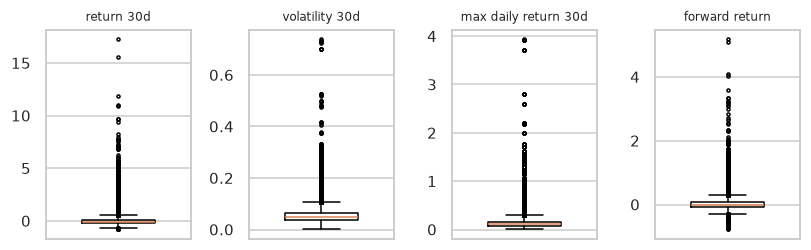

In [19]:
def iqr_bounds(s):
    q1, q3 = s.quantile([0.25, 0.75])
    return q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)


OUTLIER_COLS = ["trailing_return_30d", "trailing_volatility_30d", "max_daily_return_30d",
                "forward_return"]
rows = []
for col in OUTLIER_COLS:
    lo, hi = iqr_bounds(train_df[col].dropna())
    out = int(((train_df[col] < lo) | (train_df[col] > hi)).sum())
    rows.append({"ознака": col, "нижня межа": round(lo, 3), "верхня межа": round(hi, 3),
                 "за межами": out, "частка, %": round(out / len(train_df) * 100, 2)})
print(pd.DataFrame(rows).to_string(index=False))

fig, axes = plt.subplots(1, 4, figsize=(7.5, 2.4))
for ax, col in zip(axes, OUTLIER_COLS):
    ax.boxplot(train_df[col].dropna(), widths=0.5, flierprops={"markersize": 2})
    ax.set_title(col.replace("trailing_", "").replace("_", " "), fontsize=8)
    ax.set_xticks([])
plt.tight_layout()
plt.show()

In [20]:
extreme = train_df.nlargest(5, "forward_return")[
    ["symbol", "checkpoint", "sector", "trailing_volatility_30d", "forward_return"]]
extreme["checkpoint"] = extreme["checkpoint"].dt.date
print("П'ять найбільших тижневих дохідностей у train:")
print(extreme.round(3).to_string(index=False))
print()
print("Медіанна волатильність train:", round(train_df["trailing_volatility_30d"].median(), 4))

П'ять найбільших тижневих дохідностей у train:
  symbol checkpoint       sector  trailing_volatility_30d  forward_return
 WINUSDT 2021-03-28 Oracle/Infra                    0.095           5.173
 CHRUSDT 2021-03-07           AI                    0.117           5.105
 CHZUSDT 2021-03-07          NFT                    0.126           4.088
MOVRUSDT 2023-12-17      Layer-1                    0.042           4.032
VTHOUSDT 2021-02-07      Layer-1                    0.191           3.597

Медіанна волатильність train: 0.0489


**Генеральна сукупність і вибірка.** Генеральна сукупність - усі криптовалюти, що впевний тиждень торгувалися на публічних біржах. Вибірка - 383 монети з парою до USDTна Binance, що торгуються у вересні 2026 року. Основні зміщення: виживання (немаєделістованих монет), відбір біржею за ліквідністю, одна біржа.

## 9. Перевірка статистичних гіпотез на train**Гіпотеза 1.** H0: розподіл 30-денної волатильності однаковий для монет, щовипередили ринок, і тих, що не випередили. H1: розподіли відрізняються.Критерій Манна-Вітні, alpha = 0,05.

In [21]:
vol_win = train_df.loc[train_df["beat_market"] == 1, "trailing_volatility_30d"].dropna()
vol_lose = train_df.loc[train_df["beat_market"] == 0, "trailing_volatility_30d"].dropna()

sw_p = shapiro(vol_win.sample(5000, random_state=SEED)).pvalue
print(f"Передумова: Шапіро-Вілк для вибірки 5000, p = {sw_p:.1e} - розподіл не нормальний,")
print("тому застосовано непараметричний критерій Манна-Вітні.")
u_stat, p_h1 = mannwhitneyu(vol_win, vol_lose, alternative="two-sided")
rb_h1 = 2 * u_stat / (len(vol_win) * len(vol_lose)) - 1
print(f"n = {len(vol_win)} / {len(vol_lose)}, медіани {vol_win.median():.4f} / {vol_lose.median():.4f}")
print(f"U = {u_stat:.0f}, p-value = {p_h1:.2e}, rank-biserial = {rb_h1:.4f}")
print("Висновок:", "H0 відхиляється" if p_h1 < 0.05 else "немає підстав відхилити H0")

coin = train_df.groupby("symbol").agg(vol=("trailing_volatility_30d", "median"),
                                      win=("beat_market", "mean"), n=("beat_market", "size"))
coin = coin[coin["n"] >= 20]
u_c, p_h1_coin = mannwhitneyu(coin.loc[coin["win"] > 0.5, "vol"],
                              coin.loc[coin["win"] <= 0.5, "vol"], alternative="two-sided")
print()
print(f"Перевірка стійкості (одна точка на монету, {len(coin)} монет): p-value = {p_h1_coin:.2e}")
KEY["h1"] = dict(U=float(u_stat), p=float(p_h1), effect=float(rb_h1), p_coin=float(p_h1_coin),
                 n_coin=int(len(coin)))

Передумова: Шапіро-Вілк для вибірки 5000, p = 5.9e-65 - розподіл не нормальний,
тому застосовано непараметричний критерій Манна-Вітні.
n = 26007 / 26126, медіани 0.0475 / 0.0505
U = 310427992, p-value = 3.24e-65, rank-biserial = -0.0862
Висновок: H0 відхиляється

Перевірка стійкості (одна точка на монету, 306 монет): p-value = 7.65e-14


**Гіпотеза 2.** H0: сектор монети і подія «монета випередила ринок» незалежні.H1: між ними є зв'язок. Критерій хі-квадрат, alpha = 0,05.

In [22]:
contingency = pd.crosstab(train_df["sector"], train_df["beat_market"])
chi2, p_h2, dof, expected = chi2_contingency(contingency)
v_h2 = np.sqrt(chi2 / (contingency.values.sum() * (min(contingency.shape) - 1)))
print(f"Передумова: мінімальна очікувана частота {expected.min():.1f} (потрібно не менше 5)")
print(f"хі-квадрат = {chi2:.2f}, df = {dof}, p-value = {p_h2:.2e}, V Крамера = {v_h2:.4f}")
print("Висновок:", "H0 відхиляється" if p_h2 < 0.05 else "немає підстав відхилити H0")

coin_sector = train_df.groupby("symbol").agg(sector=("sector", "first"),
                                             win=("beat_market", "mean"),
                                             n=("beat_market", "size"))
coin_sector = coin_sector[coin_sector["n"] >= 20]
groups = [g["win"].values for _, g in coin_sector.groupby("sector") if len(g) >= 5]
h_kw, p_h2_coin = kruskal(*groups)
print()
print(f"Перевірка стійкості (одна точка на монету, Краскел-Уолліс, {len(groups)} секторів, "
      f"{sum(len(g) for g in groups)} монет):")
print(f"H = {h_kw:.2f}, p-value = {p_h2_coin:.2e}")
KEY["h2"] = dict(chi2=float(chi2), dof=int(dof), p=float(p_h2), effect=float(v_h2),
                 p_coin=float(p_h2_coin), n_sectors=len(groups),
                 n_coin=int(sum(len(g) for g in groups)))

Передумова: мінімальна очікувана частота 103.8 (потрібно не менше 5)
хі-квадрат = 111.05, df = 15, p-value = 1.01e-16, V Крамера = 0.0462
Висновок: H0 відхиляється

Перевірка стійкості (одна точка на монету, Краскел-Уолліс, 12 секторів, 296 монет):
H = 32.08, p-value = 7.41e-04


## 10. Аналіз залежностей на train

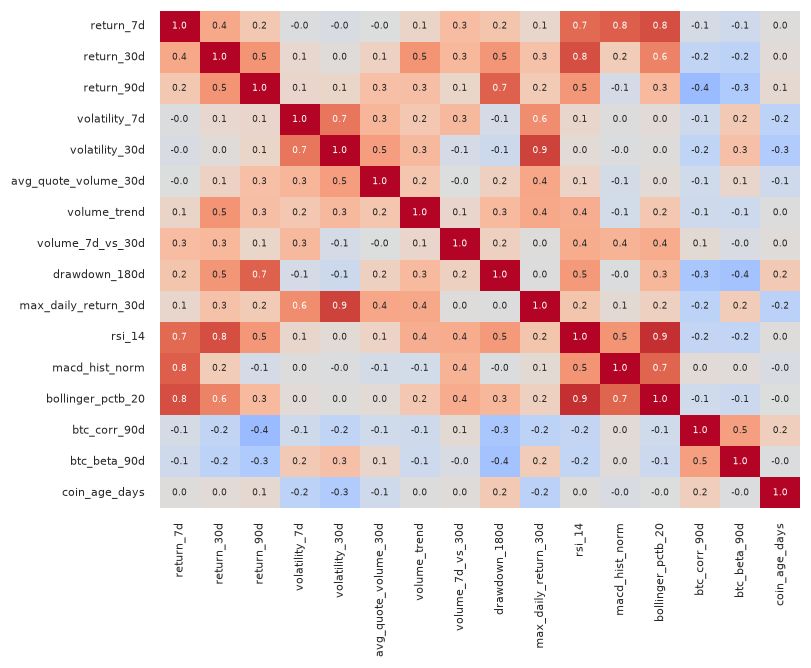

Пари з |rho| > 0,8:
  trailing_return_7d - bollinger_pctb_20: 0.817
  trailing_return_30d - rsi_14: 0.817
  trailing_volatility_30d - max_daily_return_30d: 0.859
  rsi_14 - bollinger_pctb_20: 0.908


In [23]:
corr = train_df[COIN_FEATURES].corr(method="spearman")
fig, ax = plt.subplots(figsize=(7.5, 6.2))
short = [c.replace("trailing_", "").replace("_from_high", "") for c in COIN_FEATURES]
sns.heatmap(corr, annot=True, fmt=".1f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
            annot_kws={"size": 6}, xticklabels=short, yticklabels=short, cbar=False, ax=ax)
ax.tick_params(labelsize=7)
plt.tight_layout()
plt.show()
high = [(a, b, round(corr.loc[a, b], 3)) for i, a in enumerate(COIN_FEATURES)
        for b in COIN_FEATURES[i + 1:] if abs(corr.loc[a, b]) > 0.8]
print("Пари з |rho| > 0,8:")
for a, b, r in high:
    print(f"  {a} - {b}: {r}")

In [24]:
sample = train_df.sample(20000, random_state=SEED)
num_cols = COIN_FEATURES + MARKET_FEATURES
mi = mutual_info_classif(sample[num_cols].fillna(sample[num_cols].median()),
                         sample["beat_market"], random_state=SEED)
rows = []
for col, mi_val in zip(num_cols, mi):
    s = train_df[[col, "beat_market"]].dropna()
    rows.append({"ознака": col, "r (точк.-бісер.)": round(pointbiserialr(s["beat_market"], s[col])[0], 4),
                 "взаємна інформація": round(mi_val, 4)})
for col in CAT_FEATURES:
    ct2 = pd.crosstab(train_df[col], train_df["beat_market"])
    v = np.sqrt(chi2_contingency(ct2)[0] / (ct2.values.sum() * (min(ct2.shape) - 1)))
    rows.append({"ознака": col, "r (точк.-бісер.)": np.nan, "V Крамера": round(v, 4)})
assoc = pd.DataFrame(rows)
raw_train = df_raw[df_raw["checkpoint"] <= split_week]
r_raw = pointbiserialr(raw_train["beat_market"], raw_train["trailing_volatility_30d"])[0]
print("r волатильності за 30 днів з ціллю на тих самих тижнях до структурного очищення:",
      round(r_raw, 4))
assoc.sort_values("r (точк.-бісер.)", key=abs, ascending=False, na_position="last")

r волатильності за 30 днів з ціллю на тих самих тижнях до структурного очищення: -0.0043


,ознака,r (точк.-бісер.),взаємна інформація,V Крамера
4,trailing_volatility_30d,-0.0695,0.0042,NaN
9,max_daily_return_30d,-0.0602,0.0003,NaN
3,trailing_volatility_7d,-0.0583,0.0000,NaN
15,coin_age_days,0.0562,0.0038,NaN
13,btc_corr_90d,0.0410,0.0046,NaN
7,volume_7d_vs_30d,-0.0371,0.0000,NaN
1,trailing_return_30d,-0.0330,0.0008,NaN
6,trailing_volume_trend,-0.0303,0.0000,NaN
0,trailing_return_7d,-0.0300,0.0042,NaN
10,rsi_14,-0.0297,0.0065,NaN


## 11. Перевірка витокуМомент прогнозу - закриття торгів у неділю. Для кожного стовпця вказано, чи відомийвін на цей момент, ризик витоку та рішення.

In [25]:
FUTURE = {"forward_return": "дохідність після моменту прогнозу",
          "btc_forward_return": "дохідність BTC після моменту прогнозу",
          "excess_return_vs_btc": "різниця майбутніх дохідностей",
          "market_forward_return": "медіана майбутніх дохідностей тижня",
          "relative_forward_return": "пряма похідна цілі"}
SERVICE = {"symbol": "ідентифікатор", "coingecko_id": "ідентифікатор",
           "checkpoint": "часова мітка", "close_t0": "рівень ціни без змісту для порівняння"}
rows = []
for col in df_clean.columns:
    if col == "beat_market":
        rows.append((col, "-", "-", "ціль", "цільова змінна"))
    elif col in FUTURE:
        rows.append((col, "ні", "прямий", "вилучити", FUTURE[col]))
    elif col == "missing_days_in_window":
        rows.append((col, "ні", "майбутнє", "вилучити", "індикатор якості, охоплює 7 днів після прогнозу"))
    elif col in SERVICE:
        rows.append((col, "так", "немає", "вилучити", SERVICE[col]))
    elif col == "sector":
        rows.append((col, "так", "низький", "залишити", "довідник 2026 р., сектор рідко змінюється"))
    else:
        rows.append((col, "так", "немає", "залишити", "ковзне вікно до моменту прогнозу"))
leakage = pd.DataFrame(rows, columns=["стовпець", "доступна", "ризик", "рішення", "обґрунтування"])
print(leakage["рішення"].value_counts().to_string())
leakage

рішення
залишити    21
вилучити    10
ціль         1


,стовпець,доступна,ризик,рішення,обґрунтування
0,symbol,так,немає,вилучити,ідентифікатор
1,coingecko_id,так,немає,вилучити,ідентифікатор
2,checkpoint,так,немає,вилучити,часова мітка
3,sector,так,низький,залишити,"довідник 2026 р., сектор рідко змінюється"
4,market_regime,так,немає,залишити,ковзне вікно до моменту прогнозу
5,close_t0,так,немає,вилучити,рівень ціни без змісту для порівняння
6,trailing_return_7d,так,немає,залишити,ковзне вікно до моменту прогнозу
7,trailing_return_30d,так,немає,залишити,ковзне вікно до моменту прогнозу
8,trailing_return_90d,так,немає,залишити,ковзне вікно до моменту прогнозу
9,trailing_volatility_7d,так,немає,залишити,ковзне вікно до моменту прогнозу


## 12. Конструювання ознакТри групи ознак, жодна з них не використовує цільову змінну чи майбутні ціни.

In [26]:
def engineer_features(d):
    d = d.copy()
    d["avg_quote_volume_30d"] = np.log1p(d["avg_quote_volume_30d"])
    d["relative_strength_vs_btc_90d"] = d["trailing_return_90d"] - d["btc_trailing_return_90d"]
    median_vol = d.groupby("checkpoint")["trailing_volatility_30d"].transform("median")
    d["relative_volatility_vs_market"] = d["trailing_volatility_30d"] / median_vol
    grouped = d.groupby("checkpoint")
    for col in COIN_FEATURES:
        d[f"{col}_xs"] = (grouped[col].rank(pct=True) - 0.5) * np.sqrt(12)
    return d


train_fe = engineer_features(train_df)
test_fe = engineer_features(test_df)
CONSTRUCTED = (["relative_strength_vs_btc_90d", "relative_volatility_vs_market"]
               + [f"{c}_xs" for c in COIN_FEATURES])
print("Створено ознак:", len(CONSTRUCTED))
train_fe[["relative_strength_vs_btc_90d", "relative_volatility_vs_market",
          "trailing_volatility_30d_xs"]].describe().T.drop(columns="count").style.format("{:.3f}")

Створено ознак: 18


,mean,std,min,25%,50%,75%,max
relative_strength_vs_btc_90d,-0.002,1.159,-2.795,-0.349,-0.187,0.020,41.320
relative_volatility_vs_market,1.106,0.551,0.003,0.836,1.000,1.218,17.607
trailing_volatility_30d_xs,0.009,1.000,-1.722,-0.857,0.009,0.875,1.732


In [27]:
rows = []
for col in ["relative_strength_vs_btc_90d", "relative_volatility_vs_market",
            "trailing_volatility_30d_xs", "max_daily_return_30d_xs", "coin_age_days_xs"]:
    s = train_fe[[col, "beat_market"]].dropna()
    r, p = pointbiserialr(s["beat_market"], s[col])
    auc = roc_auc_score(s["beat_market"], s[col])
    rows.append({"ознака": col, "r": round(r, 4), "ROC-AUC ознаки": round(max(auc, 1 - auc), 4),
                 "p-value": f"{p:.1e}"})
pd.DataFrame(rows)

,ознака,r,ROC-AUC ознаки,p-value
0,relative_strength_vs_btc_90d,-0.0268,0.5174,9.8e-10
1,relative_volatility_vs_market,-0.0800,0.5541,1.1e-74
2,trailing_volatility_30d_xs,-0.0932,0.5538,6.5e-101
3,max_daily_return_30d_xs,-0.0822,0.5474,8.7e-79
4,coin_age_days_xs,0.0552,0.5319,1.6e-36


## 13. Формування базового та фінального наборів ознак

In [28]:
BASE_NUM = COIN_FEATURES + MARKET_FEATURES
FINAL_NUM = BASE_NUM + CONSTRUCTED
BASE_FEATURES, FINAL_FEATURES = BASE_NUM + CAT_FEATURES, FINAL_NUM + CAT_FEATURES

top_share = train_fe[FINAL_FEATURES].apply(lambda s: s.value_counts(normalize=True).iloc[0])
print("Майже константних ознак (одне значення > 95 %):", list(top_share[top_share > 0.95].index))
print(f"Базовий набір: {len(BASE_FEATURES)} ознак ({len(BASE_NUM)} числових, 2 категоріальні)")
print(f"Фінальний набір: {len(FINAL_FEATURES)} ознак ({len(FINAL_NUM)} числових, 2 категоріальні)")
print("Вилучено:", len(FUTURE) + 1, "витокових і", len(SERVICE), "службових стовпців")

analytical = pd.concat([train_fe.assign(part="train"), test_fe.assign(part="test")])[
    ["symbol", "checkpoint", "part"] + FINAL_FEATURES + ["beat_market"]]
analytical.to_csv("data/analytical/analytical_weekly_panel.csv.gz", index=False,
                  compression="gzip", encoding="utf-8")
print("Аналітичний датасет:", analytical.shape)

Майже константних ознак (одне значення > 95 %): []
Базовий набір: 21 ознак (19 числових, 2 категоріальні)
Фінальний набір: 39 ознак (37 числових, 2 категоріальні)
Вилучено: 6 витокових і 4 службових стовпців


Аналітичний датасет: (65393, 43)


## 14. Базовий конвеєрHistGradientBoostingClassifier: змішані типи ознак, без масштабування, стійкий довикидів, нелінійні залежності. Однакові гіперпараметри в обох конвеєрах. Вбудованарання зупинка (`early_stopping="auto"`) відбирає 10 % рядків тренувальної частиникожного фолду як внутрішню валідацію; test у ній не бере участі.

In [29]:
MODEL_PARAMS = dict(random_state=SEED, learning_rate=0.05, max_iter=300,
                    max_leaf_nodes=31, min_samples_leaf=200, l2_regularization=1.0,
                    early_stopping="auto", validation_fraction=0.1)


def make_pipeline(numeric_features):
    preprocessor = ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), numeric_features),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("encode", OneHotEncoder(handle_unknown="ignore"))]), CAT_FEATURES),
    ])
    return Pipeline([("preprocessor", preprocessor),
                     ("model", HistGradientBoostingClassifier(**MODEL_PARAMS))])


base_pipeline = make_pipeline(BASE_NUM)
base_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the

## 15. Фінальний конвеєр

In [30]:
final_pipeline = make_pipeline(FINAL_NUM)
print("Той самий алгоритм і гіперпараметри; відмінність - сконструйовані ознаки:")
print("  базовий:", len(BASE_NUM), "числових ознак")
print("  фінальний:", len(FINAL_NUM), "числових ознак")

Той самий алгоритм і гіперпараметри; відмінність - сконструйовані ознаки:
  базовий: 19 числових ознак
  фінальний: 37 числових ознак


## 16. Крос-валідація обох конвеєрів на trainСхема для часових даних (аналог TimeSeriesSplit): розширюване вікно за тижнями,5 фолдів, без перемішування, embargo 1 тиждень. Фолди однакові для обох конвеєрів.

In [31]:
def time_folds(data, n_folds=5, embargo=1):
    weeks = sorted(data["checkpoint"].unique())
    start, step = len(weeks) // 2, (len(weeks) - len(weeks) // 2) // n_folds
    for i in range(n_folds):
        s = start + i * step
        valid = weeks[s:s + step] if i < n_folds - 1 else weeks[s:]
        yield weeks[:s - embargo], valid


def cross_validate(numeric_features):
    rows = []
    for i, (tr_w, va_w) in enumerate(time_folds(train_fe), start=1):
        tr = train_fe[train_fe["checkpoint"].isin(tr_w)]
        va = train_fe[train_fe["checkpoint"].isin(va_w)]
        pipe = make_pipeline(numeric_features).fit(tr[numeric_features + CAT_FEATURES],
                                                   tr["beat_market"])
        proba = pipe.predict_proba(va[numeric_features + CAT_FEATURES])[:, 1]
        pred = (proba >= 0.5).astype(int)
        y = va["beat_market"]
        rows.append({"фолд": i, "з": va_w[0].date(), "по": va_w[-1].date(),
                     "ROC-AUC": roc_auc_score(y, proba), "accuracy": accuracy_score(y, pred),
                     "bal. acc.": balanced_accuracy_score(y, pred),
                     "precision": precision_score(y, pred), "recall": recall_score(y, pred),
                     "F1": f1_score(y, pred)})
    return pd.DataFrame(rows)


cv_base = cross_validate(BASE_NUM)
cv_final = cross_validate(FINAL_NUM)
print("Базовий конвеєр:")
print(cv_base.round(4).to_string(index=False))
print("Фінальний конвеєр:")
print(cv_final.round(4).to_string(index=False))

Базовий конвеєр:
 фолд          з         по  ROC-AUC  accuracy  bal. acc.  precision  recall     F1
    1 2023-07-09 2023-12-31   0.5082    0.5057     0.5058     0.5052  0.5213 0.5131
    2 2024-01-07 2024-06-30   0.5402    0.5293     0.5293     0.5266  0.5768 0.5506
    3 2024-07-07 2024-12-29   0.5467    0.5344     0.5344     0.5317  0.5507 0.5410
    4 2025-01-05 2025-06-29   0.5482    0.5348     0.5349     0.5278  0.6554 0.5847
    5 2025-07-06 2026-01-04   0.5543    0.5427     0.5427     0.5390  0.5829 0.5601
Фінальний конвеєр:
 фолд          з         по  ROC-AUC  accuracy  bal. acc.  precision  recall     F1
    1 2023-07-09 2023-12-31   0.5225    0.5142     0.5142     0.5132  0.5366 0.5246
    2 2024-01-07 2024-06-30   0.5698    0.5531     0.5532     0.5485  0.5992 0.5727
    3 2024-07-07 2024-12-29   0.5628    0.5483     0.5483     0.5454  0.5629 0.5540
    4 2025-01-05 2025-06-29   0.5554    0.5364     0.5364     0.5323  0.5953 0.5620
    5 2025-07-06 2026-01-04   0.5629    

## 17. Порівняння результатів

In [32]:
better = int((cv_final["ROC-AUC"] > cv_base["ROC-AUC"]).sum())
summary_cv = pd.DataFrame([
    {"конвеєр": name, "ROC-AUC, середнє": cv["ROC-AUC"].mean(), "ROC-AUC, std": cv["ROC-AUC"].std(),
     "accuracy": cv["accuracy"].mean(), "bal. acc.": cv["bal. acc."].mean(),
     "precision": cv["precision"].mean(), "recall": cv["recall"].mean(), "F1": cv["F1"].mean()}
    for name, cv in [("базовий", cv_base), ("фінальний", cv_final)]]).round(4)
summary_cv["висновок"] = ["точка відліку", f"обрано: кращий у {better} з 5 фолдів"]
KEY["cv"] = summary_cv.to_dict("records")
summary_cv

,конвеєр,"ROC-AUC, середнє","ROC-AUC, std",accuracy,bal. acc.,precision,recall,F1,висновок
0,базовий,0.5395,0.0182,0.5294,0.5294,0.5261,0.5774,0.5499,точка відліку
1,фінальний,0.5547,0.0187,0.5391,0.5391,0.5351,0.5859,0.5590,обрано: кращий у 5 з 5 фолдів


## 18. Навчання фінального конвеєра на всьому train

In [33]:
X_train, y_train = train_fe[FINAL_FEATURES], train_fe["beat_market"]
final_pipeline.fit(X_train, y_train)
print("Фінальний конвеєр навчено на", len(X_train), "записах train.")
print("Ітерацій бустингу після ранньої зупинки:", final_pipeline["model"].n_iter_)

Фінальний конвеєр навчено на 52133 записах train.
Ітерацій бустингу після ранньої зупинки: 231


## 19. Одноразове оцінювання на test

In [34]:
X_test, y_test = test_fe[FINAL_FEATURES], test_fe["beat_market"]
y_proba = final_pipeline.predict_proba(X_test)[:, 1]
y_pred = (y_proba >= 0.5).astype(int)
test_metrics = pd.Series({
    "ROC-AUC": roc_auc_score(y_test, y_proba), "accuracy": accuracy_score(y_test, y_pred),
    "balanced accuracy": balanced_accuracy_score(y_test, y_pred),
    "precision": precision_score(y_test, y_pred), "recall": recall_score(y_test, y_pred),
    "F1": f1_score(y_test, y_pred)}).round(4)
KEY["test"] = test_metrics.to_dict()
print(test_metrics.to_string())

ROC-AUC              0.5503
accuracy             0.5344
balanced accuracy    0.5344
precision            0.5316
recall               0.5714
F1                   0.5508


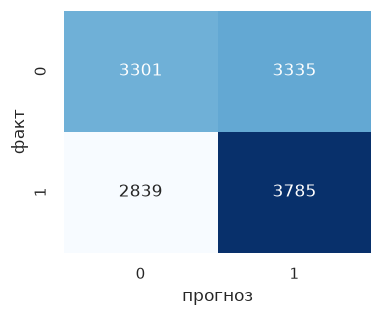

               precision    recall  f1-score   support

не випередила       0.54      0.50      0.52      6636
   випередила       0.53      0.57      0.55      6624

     accuracy                           0.53     13260
    macro avg       0.53      0.53      0.53     13260
 weighted avg       0.53      0.53      0.53     13260



In [35]:
fig, ax = plt.subplots(figsize=(3.6, 3.0))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["0", "1"], yticklabels=["0", "1"], ax=ax)
ax.set_xlabel("прогноз")
ax.set_ylabel("факт")
plt.tight_layout()
plt.show()
print(classification_report(y_test, y_pred, target_names=["не випередила", "випередила"]))

In [36]:
test_eval = test_fe.assign(correct=(y_pred == y_test).values, proba=y_proba)
by_regime = test_eval.groupby("market_regime").apply(lambda g: pd.Series({
    "ROC-AUC": roc_auc_score(g["beat_market"], g["proba"]), "точність": g["correct"].mean(),
    "записів": len(g)}))
by_sector = test_eval.groupby("sector")["correct"].agg(точність="mean", записів="count")
print("За ринковим режимом:")
print(by_regime.round(4).to_string())
print()
print("Сектори з найнижчою і найвищою точністю:")
print(pd.concat([by_sector.nsmallest(3, "точність"), by_sector.nlargest(3, "точність")])
      .round(4).to_string())

За ринковим режимом:
               ROC-AUC  точність  записів
market_regime                            
bear            0.5488    0.5315   9131.0
bull            0.5939    0.5704   1876.0
sideways        0.5206    0.5162   2253.0

Сектори з найнижчою і найвищою точністю:
                  точність  записів
sector                             
Metaverse/Gaming    0.4444       72
Privacy             0.4815      108
DeFi                0.5074     1547
Stablecoin          0.6009      218
Exchange Token      0.5694       72
Layer-2             0.5589      798


In [37]:
dummy = DummyClassifier(strategy="most_frequent", random_state=SEED).fit(X_train, y_train)
base_pipeline.fit(train_fe[BASE_FEATURES], y_train)
base_test_auc = roc_auc_score(y_test, base_pipeline.predict_proba(test_fe[BASE_FEATURES])[:, 1])
stages = pd.DataFrame({
    "етап": ["наївний класифікатор", "базовий, крос-валідація", "фінальний, крос-валідація",
             "базовий, test (довідково)", "фінальний, test"],
    "ROC-AUC": [roc_auc_score(y_test, dummy.predict_proba(X_test)[:, 1]),
                cv_base["ROC-AUC"].mean(), cv_final["ROC-AUC"].mean(),
                base_test_auc, test_metrics["ROC-AUC"]]}).round(4)
KEY["base_test_auc"] = float(base_test_auc)
stages

,етап,ROC-AUC
0,наївний класифікатор,0.5000
1,"базовий, крос-валідація",0.5395
2,"фінальний, крос-валідація",0.5547
3,"базовий, test (довідково)",0.5349
4,"фінальний, test",0.5503


In [38]:
weekly = []
for cp, g in test_eval.groupby("checkpoint"):
    k = max(1, round(len(g) * 0.2))
    weekly.append({"checkpoint": cp, "топ-20 %": g.nlargest(k, "proba")["forward_return"].mean(),
                   "нижні 20 %": g.nsmallest(k, "proba")["forward_return"].mean(),
                   "медіанна монета": g["forward_return"].median(),
                   "BTC": g["btc_forward_return"].iloc[0]})
weekly = pd.DataFrame(weekly).set_index("checkpoint")
weekly["топ мінус нижні"] = weekly["топ-20 %"] - weekly["нижні 20 %"]
print(f"Тестовий період: {len(weekly)} тижнів. Середня дохідність за тиждень, %:")
print((weekly.mean() * 100).round(2).to_string())
print("Частка тижнів у плюсі:")
print((weekly > 0).mean().round(3).to_string())

Тестовий період: 36 тижнів. Середня дохідність за тиждень, %:
топ-20 %           0.09
нижні 20 %        -0.85
медіанна монета   -1.89
BTC               -0.11
топ мінус нижні    0.94
Частка тижнів у плюсі:
топ-20 %           0.472
нижні 20 %         0.472
медіанна монета    0.361
BTC                0.472
топ мінус нижні    0.583


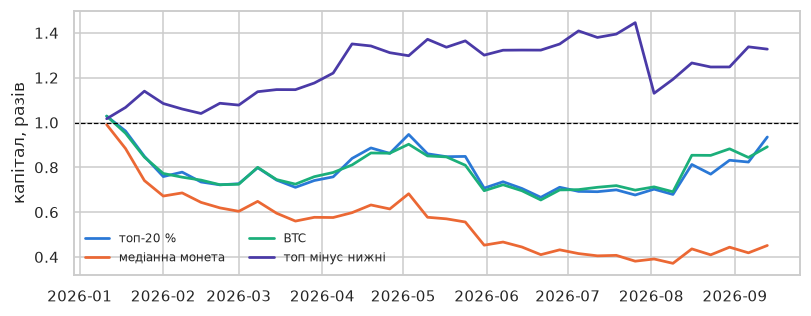

Підсумок за тестовий період, разів:
топ-20 % 0.936; медіанна монета 0.452; BTC 0.892; топ мінус нижні 1.328


In [39]:
equity = (1 + weekly[["топ-20 %", "медіанна монета", "BTC", "топ мінус нижні"]]).cumprod()
fig, ax = plt.subplots(figsize=(7.5, 3.0))
for col, color in zip(equity.columns, ["#2a78d6", "#eb6834", "#1baf7a", "#4a3aa7"]):
    ax.plot(equity.index, equity[col], label=col, color=color, linewidth=1.8)
ax.axhline(1.0, color="black", linewidth=0.8, linestyle="--")
ax.set_ylabel("капітал, разів")
ax.legend(frameon=False, fontsize=8, ncol=2)
plt.tight_layout()
plt.show()
print("Підсумок за тестовий період, разів:")
print("; ".join(f"{k} {v:.3f}" for k, v in equity.iloc[-1].items()))

In [40]:
in_sample_auc = roc_auc_score(y_train, final_pipeline.predict_proba(X_train)[:, 1])
KEY["in_sample_auc"] = float(in_sample_auc)
print("ROC-AUC на train (модель бачила ці дані):", round(in_sample_auc, 4))
print("ROC-AUC на test (чесна оцінка):         ", test_metrics["ROC-AUC"])
with open("results/key_numbers.json", "w", encoding="utf-8") as f:
    json.dump(KEY, f, ensure_ascii=False, indent=1, default=float)

ROC-AUC на train (модель бачила ці дані): 0.7608
ROC-AUC на test (чесна оцінка):          0.5503


## 20. Підсумкові висновкиФінальний конвеєр перевершив базовий на крос-валідації й на test; результат на test непоступається крос-валідації, тобто ознак перенавчання чи витоку немає. Ключові числазбережено в `results/key_numbers.json`, текст висновків - у курсовій роботі.